In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import string
from wordcloud import WordCloud
from textblob import TextBlob
!pip install --upgrade jupyter_client jupyter-core
!pip install pyLDAvis
import pyLDAvis
import pyLDAvis.lda_model
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import matplotlib.ticker as ticker

# Download latest version
path1 = kagglehub.dataset_download("tiagoadrianunes/imdb-top-5000-movies")
path2 = kagglehub.dataset_download("shivvm/popular-movies-imdb-reviews-dataset")


print("Path to dataset files:", path1)
print("Path to dataset files:", path2)

#Load data

%cd {path1}

data1 = pd.read_csv("results_with_crew.csv")

%cd {path2}

data2 = pd.read_csv("imdb_list.csv")
data3 = pd.read_csv("imdb_reviews.csv")

%cd {path3}

#get list of attributes from data1
data1.columns

#drop unneeded attributes from data1
data1.drop('IMDbLink', axis=1, inplace=True)
data1.drop('Title_IMDb_Link', axis=1, inplace=True)
data1.drop('rank', axis=1, inplace=True)
data1.drop('startYear', axis=1, inplace=True)

#get list of attributes from data2
data2.columns

#drop unneeded attributes from data2
data2.drop('Unnamed: 0', axis=1, inplace=True)
data2.head()

#left join data1 tconst to data2 on id
data2 = pd.merge(data2, data1, left_on='id', right_on='tconst', how='left')
len(data2)

#dropping rows from data2 that have values with NaN in any column
data2.replace("NaN", np.nan, inplace=True)
data2.dropna(inplace=True)

#get rid of duplicate rows
data2.drop_duplicates(subset=['id'], inplace=True)

#check how many reviews we have for each film
data3.groupby('imdb_id').count()['review'].sort_values(ascending=False)

  Using cached pyLDAvis-3.4.1-py3-none-any.whl.metadata (4.2 kB)
  Using cached funcy-2.0-py2.py3-none-any.whl.metadata (5.9 kB)
  Using cached gensim-4.4.0-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (8.4 kB)
Using cached pyLDAvis-3.4.1-py3-none-any.whl (2.6 MB)
Using cached funcy-2.0-py2.py3-none-any.whl (30 kB)
Using cached gensim-4.4.0-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl (27.9 MB)
Using Colab cache for faster access to the 'imdb-top-5000-movies' dataset.
Using Colab cache for faster access to the 'popular-movies-imdb-reviews-dataset' dataset.
Path to dataset files: /kaggle/input/imdb-top-5000-movies
Path to dataset files: /kaggle/input/popular-movies-imdb-reviews-dataset
/kaggle/input/imdb-top-5000-movies
/kaggle/input/popular-movies-imdb-reviews-dataset
[Errno 2] No such file or directory: '{path3}'
/kaggle/input/popular-movies-imdb-reviews-dataset


,review
imdb_id,
tt1431045,50
tt0369610,25
tt0478970,25
tt0490215,25
tt0974015,25
...,...
tt4154796,24
tt6857112,24
tt7991608,24


In [ ]:
#Combing the datasets so we only have films that are within both datasets
data3 = data3[data3['imdb_id'].isin(data2['id'])]
data2 = data2[data2['id'].isin(data3['imdb_id'])]
movies = data2
reviews = data3
print(len(movies))

220


In [ ]:
# Download latest version
path3 = kagglehub.dataset_download("akshaypawar7/millions-of-movies")

print("Path to dataset files:", path3)

%cd {path3}

test = pd.read_csv("movies.csv")
test = test[['title','revenue', 'budget']]
test = test.drop_duplicates(subset=['title'])
test = test.dropna()
movies = movies.merge(test, left_on='title', right_on='title', how='left')
print(len(movies))
len(movies[movies['revenue']==0])

#drop revnue == 0 from movies
movies = movies[movies['revenue']!=0]
print(len(movies))

Using Colab cache for faster access to the 'millions-of-movies' dataset.
Path to dataset files: /kaggle/input/millions-of-movies
/kaggle/input/millions-of-movies
220
194


In [ ]:
#printing revenue and budget of "Jurassic World" and "Inside Out"
print(movies[movies['title']=='Jurassic World'])
print(movies[movies['title']=='Inside Out'])

          id           title  rating                      genre  year  \
0  tt0369610  Jurassic World     6.9  Action, Adventure, Sci-Fi  2015   

      tconst    primaryTitle  averageRating  numVotes  runtimeMinutes  \
0  tt0369610  Jurassic World            6.9  728455.0           124.0   

         directors                                            writers  \
0  Colin Trevorrow  Amanda Silver, Colin Trevorrow, Rick Jaffa, Mi...   

                      genres       revenue       budget  
0  Action, Adventure, Sci-Fi  1.671537e+09  150000000.0  
           id       title  rating                         genre  year  \
19  tt2096673  Inside Out     8.1  Animation, Adventure, Comedy  2015   

       tconst primaryTitle  averageRating  numVotes  runtimeMinutes  \
19  tt2096673   Inside Out            8.1  913147.0            95.0   

                         directors  \
19  Ronnie Del Carmen, Pete Docter   

                                              writers  \
19  Bill Hader, Ron

Decision Tree

Box office tier distribution:
box_office_tier
Low       65
Medium    64
High      65
Name: count, dtype: int64

Decision Tree — Box Office Tier Classification Report:
              precision    recall  f1-score   support

         Low       0.78      0.82      0.80        22
      Medium       0.61      0.64      0.62        22
        High       0.38      0.33      0.36        15

    accuracy                           0.63        59
   macro avg       0.59      0.60      0.59        59
weighted avg       0.62      0.63      0.62        59



<Figure size 600x400 with 0 Axes>

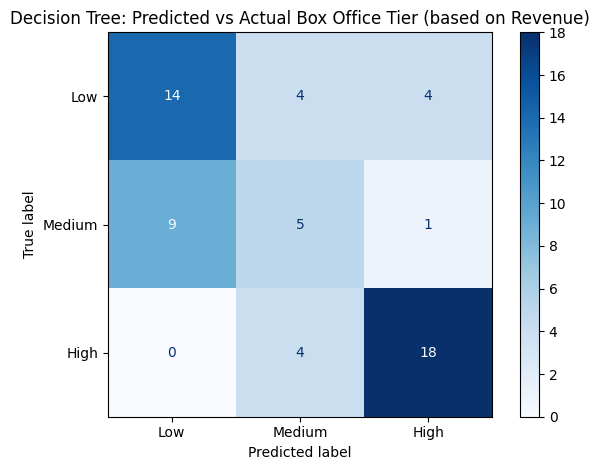

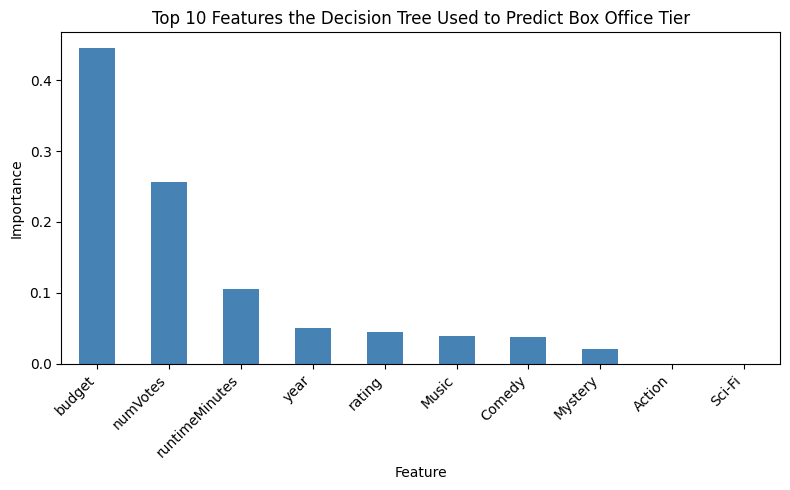

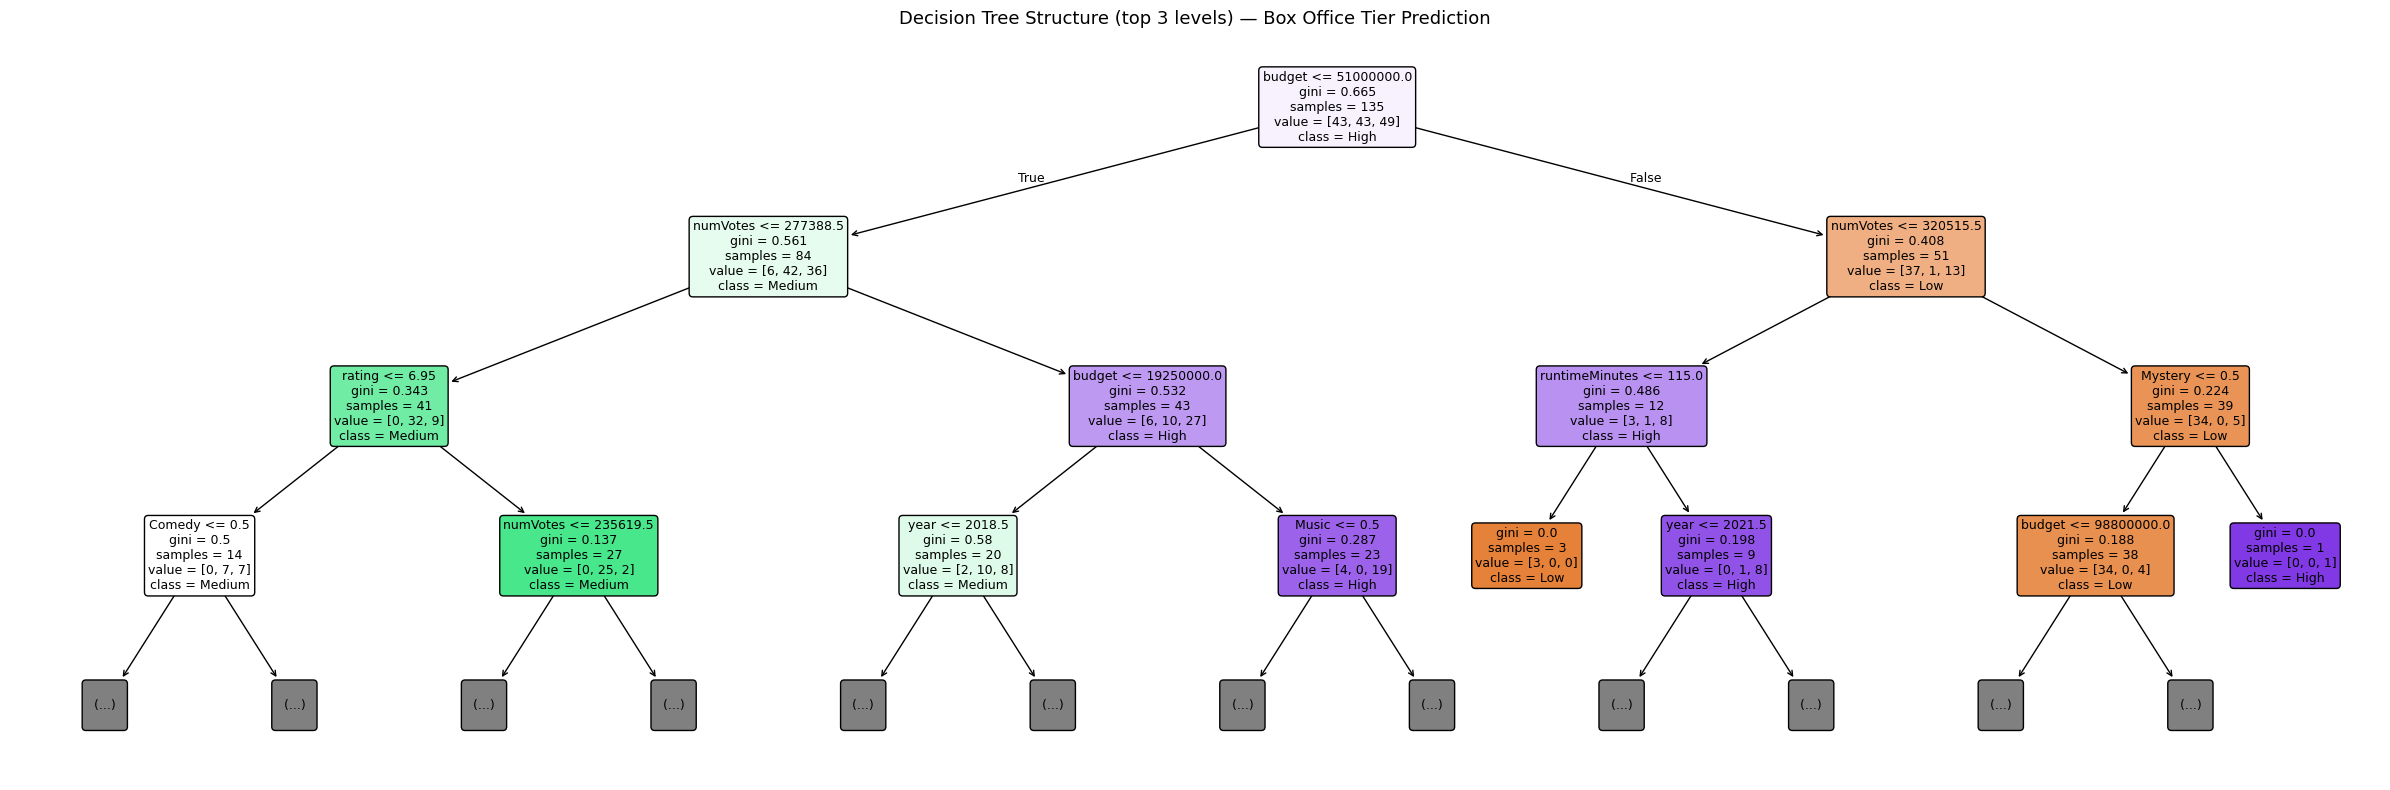

In [ ]:
"""
DECISION TREE CLASSIFICATION — Predicting Box Office Performance (Low / Medium / High)

Goal: Predict how well a movie will perform at the box office (revenue),
classified into three tiers:
  - Low    = lowest third of revenue earners
  - Medium = middle third of revenue earners
  - High   = top third of revenue earners

Features used to make this prediction:
  year, numVotes, runtimeMinutes, budget, rating, and genre
"""

# subsetting
classification = movies.copy()

# dropping variables not being used
classification = classification.drop(['id', 'title', 'averageRating', 'tconst',
                                       'primaryTitle', 'writers', 'directors'], axis=1)

# breaking up genres into individual genres and assigning as binary columns
for genre in classification['genres'].str.split(',').explode().str.strip().unique():
    classification.loc[classification['genres'].str.contains(genre, na=False), genre] = 1
classification = classification.fillna(0)

# get genre column names
genre_cols = classification.columns[8:].tolist()

# convert genre columns to integer
for col in genre_cols:
    if col in classification.columns:
        classification[col] = classification[col].astype(int)

# drop original genres column
classification = classification.drop(['genres'], axis=1)


# CREATE TARGET: box office performance tier based on revenue
# We split revenue into 3 equal-sized groups so each tier has a fair
# number of movies to learn from
classification['box_office_tier'] = pd.qcut(
    classification['revenue'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

# drop rows where tier couldn't be assigned
classification = classification.dropna(subset=['box_office_tier'])

print("Box office tier distribution:")
print(classification['box_office_tier'].value_counts().sort_index())
print()


# SET UP FEATURES AND TARGET
# revenue is excluded from features — it's what we're trying to predict
# rating is kept in as a predictor (audience score as a signal of performance)
other_features = ['year', 'numVotes', 'runtimeMinutes', 'budget', 'rating']
X_features = other_features + genre_cols

X = classification[X_features]
y = classification['box_office_tier']

# drop rows with missing values
X = X.dropna()
y = y[X.index]


# TRAIN / TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


# TRAIN DECISION TREE CLASSIFIER
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

dt_classifier = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_classifier.fit(X_train, y_train)

y_pred = dt_classifier.predict(X_test)


# MODEL METRICS
print("Decision Tree — Box Office Tier Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Low', 'Medium', 'High']))


# CONFUSION MATRIX
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred, labels=['Low', 'Medium', 'High'])
disp = ConfusionMatrixDisplay(cm, display_labels=['Low', 'Medium', 'High'])
disp.plot(cmap='Blues')
plt.title('Decision Tree: Predicted vs Actual Box Office Tier (based on Revenue)')
plt.tight_layout()
plt.show()


# FEATURE IMPORTANCES
importances = pd.Series(dt_classifier.feature_importances_, index=X_features)
top_features = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
top_features.plot(kind='bar', color='steelblue')
plt.title('Top 10 Features the Decision Tree Used to Predict Box Office Tier')
plt.xlabel('Feature')
plt.ylabel('Importance')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


# DECISION TREE VISUALISATION
# Shows the actual splits the tree makes at each node.
# max_depth=3 keeps it readable — the full depth=5 tree is too wide to display clearly.
plt.figure(figsize=(24, 8))
plot_tree(
    dt_classifier,
    max_depth=3,                          # show top 3 levels for readability
    feature_names=X_features,
    class_names=['Low', 'Medium', 'High'],
    filled=True,                          # colour nodes by majority class
    rounded=True,
    fontsize=9
)
plt.title('Decision Tree Structure (top 3 levels) — Box Office Tier Prediction', fontsize=13)
plt.tight_layout()
plt.show()

**TEXT ANALYTICS**

In [ ]:
#Getting the amount of unique words
def unique_words():
  unique_word_count = reviews['review'].str.split().explode().nunique()
  print(f'There are {unique_word_count} unique words in total')
unique_words()

There are 93708 unique words in total


In [ ]:
#Getting the top frequent words
def top_frequent_words(n=20):
  top_n = reviews['review'].str.split().explode().value_counts().head(n)
  print(f'The {n} most common words:')
  print(top_n)
top_frequent_words(20)

The 20 most common words:
review
the      69989
and      41007
a        37369
of       33061
to       31983
is       24798
in       19208
that     16143
I        16030
it       14430
this     11784
was      11085
with     10941
as       10140
for       9949
but       9411
The       8535
movie     7600
film      7344
are       6891
Name: count, dtype: int64


In [ ]:
#Removing punctuations and converting text to lowercase
import string
reviews['review'] = reviews['review'].str.replace(f'[{string.punctuation}]+', ' ', regex=True)
reviews['review'] = reviews['review'].str.lower()
unique_words()

There are 33602 unique words in total


In [ ]:
#Combing out basic stop words within the nltk stopwords library
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
stop = stopwords.words('english')
reviews['review'] = reviews['review'].apply(lambda x: ' '.join([x for x in x.split() if x not in (stop)]))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
#Checking status of functions to see how data looks after combing
top_frequent_words(20)
unique_words()

The 20 most common words:
review
movie         10756
film          10535
one            5671
like           5100
story          4304
good           3635
really         3258
time           3108
well           3053
great          2929
also           2896
much           2869
characters     2718
would          2698
character      2675
even           2641
see            2617
first          2336
way            2239
action         2157
Name: count, dtype: int64
There are 33449 unique words in total


In [ ]:
#Applying custom stop words unique to this dataset & recombing
# Lowercase, remove punctuation, and split titles into words
movie_titles = movies['title'].fillna('').str.lower().str.replace(f'[{string.punctuation}]+', ' ', regex=True).str.split()
movie_titles = [word for sublist in movie_titles for word in sublist]

# Lowercase and split directors into words
movie_directors = movies['directors'].fillna('').str.lower().str.split()
movie_directors = [word for sublist in movie_directors for word in sublist]


stop = set(stop)

stop.update(movie_titles)
stop.update(movie_directors)
stop.update(['movie', 'movies', 'film', 'films', 'would', 'also', 'watch', 'get', 'see'])

#converts to a list to break any errors due to pandas dataframe
stop = list(stop)

stop = [
    str(w)
    for w in stop
    if isinstance(w, (str, int, float))
]

reviews['review'] = reviews['review'].apply(lambda x: ' '.join([x for x in x.split() if x not in (stop)]))
unique_words()
top_frequent_words(20)

There are 32866 unique words in total
The 20 most common words:
review
like          5100
good          3635
really        3258
well          3053
great         2929
much          2869
characters    2718
character     2675
even          2641
first         2336
action        2157
best          2068
people        1983
could         1889
make          1791
many          1737
think         1734
scenes        1662
plot          1586
feel          1572
Name: count, dtype: int64


In [ ]:
#Applying stemming technique to coalesce alike words
from nltk.stem import PorterStemmer
st = PorterStemmer()
reviews['review'] = reviews['review'].apply(lambda x: ' '.join([st.stem(word) for word in x.split()]))
unique_words()
top_frequent_words(20)

There are 21313 unique words in total
The 20 most common words:
review
like       5810
charact    5395
good       3693
make       3552
realli     3258
well       3059
scene      3010
feel       2984
great      2972
much       2869
even       2682
end        2580
go         2421
love       2353
first      2337
action     2312
best       2072
think      2069
act        2043
peopl      1994
Name: count, dtype: int64


In [ ]:
#starting to assign values
from textblob import TextBlob

results = []
for review in reviews['review']:
  blob = TextBlob(review)
  polarity = blob.sentiment.polarity
  if polarity > 0.5:
    sentiment = 'Very Positive'
  elif polarity > 0:
    sentiment = 'Positive'
  elif polarity < 0:
    sentiment = 'Negative'
  elif polarity < -0.5:
    sentiment = 'Very Negative'
  else:
    sentiment = 'Neutral'
  results.append({'review':review,'Sentiment':sentiment,'Polarity':polarity})

#checking output
results_df = pd.DataFrame(results)
results_df.head()


,review,Sentiment,Polarity
0,may heard critic champion best sequel fan decl...,Positive,0.204704
1,origin still person enorm fun thrill nail bite...,Positive,0.174237
2,4th seri second sequel direct start well enoug...,Positive,0.185943
3,let start state much hard fan love alway alway...,Positive,0.158160
4,modern polish entri seri pick 22 year origin s...,Positive,0.182652


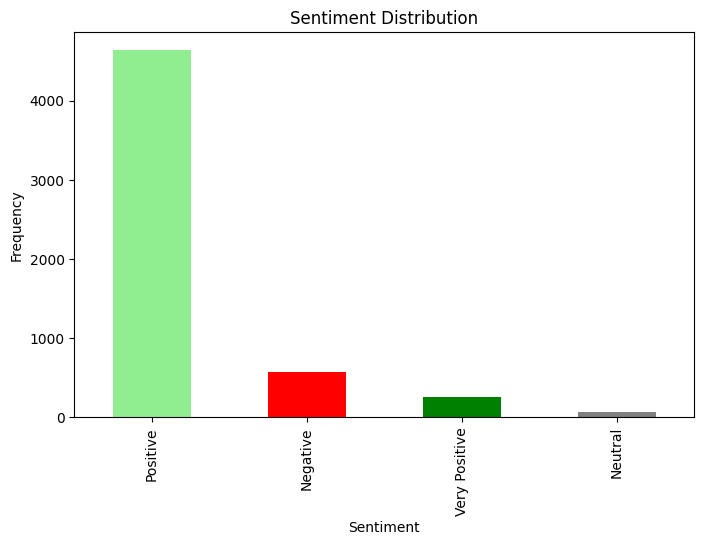

In [ ]:
#generating bar chart visualization of sentiment
plt.figure(figsize=(8,5))
results_df['Sentiment'].value_counts().plot(kind='bar',color=['lightgreen','red','green','gray','darkred'])
plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Frequency')
plt.show()

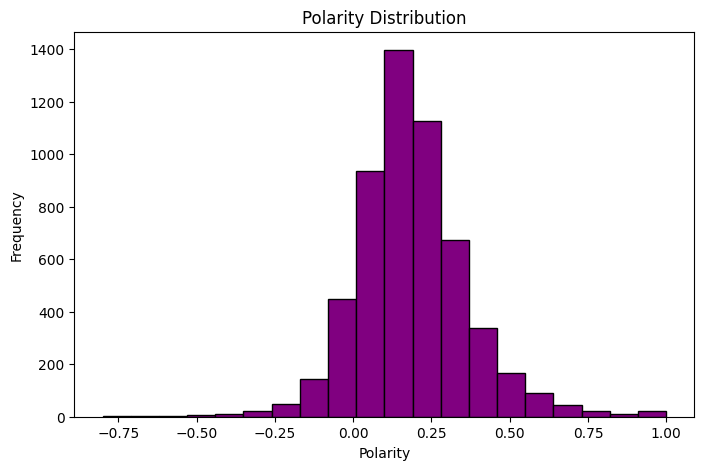

In [ ]:
#generating histogram chart to view distribution of polarity
plt.figure(figsize=(8,5))
plt.hist(results_df['Polarity'],bins=20,color='purple',edgecolor='black')
plt.title('Polarity Distribution')
plt.xlabel('Polarity')
plt.ylabel('Frequency')
plt.show()

In [ ]:
import pyLDAvis
import pyLDAvis.lda_model

# Topic Models
#Most important topics for each genre
#Or recommend based on topics or labels

#topic modeling of text
vectorizer = CountVectorizer(max_df=0.1, min_df=65, stop_words='english')

# Join the list of words back into a single string for CountVectorizer
processed_text_for_lda = reviews['review'].apply(lambda x: ' '.join(x.split()))
vectorized_text = vectorizer.fit_transform(processed_text_for_lda)

lda_text = LatentDirichletAllocation(n_components=4, random_state=42)
lda_text.fit(vectorized_text)

feature_names = vectorizer.get_feature_names_out()
term_frequency = np.sum(vectorized_text, axis=0).tolist()[0]
lda_data = pyLDAvis.lda_model.prepare(lda_text, vectorized_text, vectorizer, vocab = feature_names, term_frequency = term_frequency, n_jobs = 1)

for topic_idx, topic in enumerate(lda_text.components_):
    print(f'Topic {topic_idx + 1}:')
    top_words_indices = topic.argsort()[:-11:-1]
    top_words = [feature_names[i] for i in top_words_indices]
    print(', '.join(top_words))
    print()


Topic 1:
fight, marvel, villain, sequenc, hero, bond, franchis, comic, superhero, seri

Topic 2:
oscar, power, drama, narr, portray, true, truli, relationship, score, leav

Topic 3:
horror, half, bore, disappoint, lack, write, develop, dialogu, script, twist

Topic 4:
anim, kid, girl, disney, friend, everyon, theater, saw, voic, race



In [ ]:
pyLDAvis.enable_notebook()
lda_data

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
1      0.053058  0.086915       1        1  33.322708
2     -0.043156 -0.018685       2        1  24.631106
3      0.075910 -0.069704       3        1  21.205249
0     -0.085812  0.001475       4        1  20.840937, topic_info=       Term        Freq       Total Category  logprob  loglift
55     anim  701.000000  701.000000  Default  30.0000  30.0000
655  marvel  569.000000  569.000000  Default  29.0000  29.0000
427   fight  671.000000  671.000000  Default  28.0000  28.0000
513    hero  428.000000  428.000000  Default  27.0000  27.0000
529  horror  854.000000  854.000000  Default  26.0000  26.0000
..      ...         ...         ...      ...      ...      ...
299   deliv  189.704709  619.645273   Topic4  -5.5929   0.3846
445  follow  185.602586  636.264710   Topic4  -5.6148   0.3362
957    sinc  182.991807  615.707495   Topic4  -5.6289   0.3549
628    line  173.453703  558.625518   Topic4  -5.6825   0.3987
838    rate  169.989566  577.461045   Topic4  -5.7026   0.3453

[258 rows x 6 columns], token_table=      Topic      Freq     Term
term                          
0         1  0.153208      100
0         2  0.112352      100
0         3  0.663900      100
0         4  0.061283      100
17        1  0.167961  absolut
...     ...       ...      ...
1190      4  0.084789    write
1198      1  0.086722     zero
1198      2  0.755722     zero
1198      3  0.123889     zero
1198      4  0.024778     zero

[761 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[2, 3, 4, 1])

In [ ]:
#get probability distribution across N (your choice before) topics for each doument
doc_topic_dist = lda_text.transform(vectorized_text)

#find top 5 most representative documents in each topic
for topic_num in range(lda_text.n_components):
  print(f'\n====== Representative Documents for Topic {topic_num} =========')
  #get doc indices with highest probability for this topic
  top_doc_indices = np.argsort(doc_topic_dist[:,topic_num])[-5:][::-1]

  for idx in top_doc_indices:
    print(f'\nDocument {idx} (topic probability: {doc_topic_dist[idx,topic_num]:.3f})')
    print(reviews.iloc[idx]['review'][:200]) #shows first 200 characters of the review


====== Representative Documents for Topic 0 =========

Document 515 (topic probability: 0.994)
whether like craig bond deni integr seri highest point casino royal action thriller ever let alon bond skyfal right goldeney quintessenti bond adventur follow skyfal huge shoe fill deliv exactli expec

Document 308 (topic probability: 0.994)
2015 marvel damn good superhero flick excel sequel ye mile better termin genisi enjoy much better termin new fun popcorn action entertain action sequel flick like first love much first like work secon

Document 4456 (topic probability: 0.992)
last 169 minut idea flew right pull punch engag safeti fu epic combat scene moment much entir act amount stunt choreographi everybodi synchron rather incred continu find way entertain kill kill type u

Document 507 (topic probability: 0.992)
skyfal deconstruct bond reconstruct craig return 007 mark fourth potenti final outing charact bond follow cryptic messag lead crimin organ known first craig bond feel like conne

In [ ]:
# attach sentiment to reviews_df
reviews_df = pd.DataFrame(results)

# merge movie ID back in
reviews_df['imdb_id'] = reviews['imdb_id'].values

#Get average sentiment for each movie via imdb id
movie_sentiment = reviews_df.groupby('imdb_id')['Polarity'].mean().reset_index()
movie_sentiment.columns = ['imdb_id', 'avg_sentiment']

#merging data
movie_features = movies.merge(movie_sentiment, left_on='id', right_on='imdb_id')

#getting avg rating and movies with top votes for weighted calc
C = movie_features['rating'].mean()
m = movie_features['numVotes'].quantile(0.75)

#weighing ratings based on votes and rating
movie_features['weighted_rating'] = (
    (movie_features['numVotes'] / (movie_features['numVotes'] + m)) * movie_features['rating']
    + (m / (movie_features['numVotes'] + m)) * C
)

#creating final scoring w/ even weights for weighted rating and sentiment rating
movie_features['final_score'] = (
    0.5 * movie_features['weighted_rating'] +
    0.5 * movie_features['avg_sentiment']
)


In [ ]:
#Attach LDA outputs to reviews
lda_reviews = reviews.copy()

# topic distribution from LDA
doc_topic_dist = lda_text.transform(vectorized_text)

# add dominant topic per review
lda_reviews['imdb_id'] = reviews['imdb_id'].values
lda_reviews['dominant_topic'] = doc_topic_dist.argmax(axis=1)


#Aggregate to movie level and count topic distribution as percentages
movie_topic_dist = (
    lda_reviews
    .groupby('imdb_id')['dominant_topic']
    .value_counts(normalize=True)
    .unstack(fill_value=0)
)

# ensure all topics exist as columns
for i in range(lda_text.n_components):
    if i not in movie_topic_dist.columns:
        movie_topic_dist[i] = 0

movie_topic_dist = movie_topic_dist.sort_index(axis=1)


# derive dominant topic + strength
movie_topic_dist['main_topic'] = movie_topic_dist.idxmax(axis=1)
movie_topic_dist['topic_strength'] = movie_topic_dist.max(axis=1)

#  entropy or uncertainty (diversity between topics)
movie_topic_dist['topic_entropy'] = -np.sum(
    movie_topic_dist.iloc[:, :-2] * np.log(movie_topic_dist.iloc[:, :-2] + 1e-10),
    axis=1
)

#creating a dictionary of the topics for easier access
topic_labels = {
    0: "Action/Comedy/Franchise",
    1: "Animated/Family/Musical",
    2: "Drama/Biographical/Relationships",
    3: "Horror/Thriller/Sound"
}

movie_topic_dist['main_topic_label'] = movie_topic_dist['main_topic'].map(topic_labels)


#Merge into movie dataset
movies_final = movie_features.merge(
    movie_topic_dist,
    left_on='id',
    right_index=True,
    how='left'
)

# fill missing topic values for movies with no matched reviews
movies_final['topic_strength'] = movies_final['topic_strength'].fillna(0)
movies_final['topic_entropy'] = movies_final['topic_entropy'].fillna(0)
movies_final['main_topic'] = movies_final['main_topic'].fillna(-1)
movies_final['main_topic_label'] = movies_final['main_topic_label'].fillna('Unknown')

# normalize features so the weights are meaningful
max_entropy = np.log(lda_text.n_components)
movies_final['weighted_rating'] = movies_final['weighted_rating'] / 10

movies_final['final_topic_adjusted_score'] = (
    (movies_final['weighted_rating']).clip(0, 1) * 0.60 +
    ((movies_final['avg_sentiment'] + 1) / 2).clip(0, 1) * 0.25 +
    movies_final['topic_strength'].clip(0, 1) * 0.15 -
    (movies_final['topic_entropy'] / max_entropy).clip(0, 1) * 0.05
).clip(0, 1)

# make this the score used later in recommendations
movies_final['final_score'] = movies_final['final_topic_adjusted_score']

Topic 1:
horror, life, someth, think, play, peopl, act, use, scene, mani

Topic 2:
bad, peopl, end, good, realli, scene, know, lot, plot, want

Topic 3:
feel, perform, realli, end, plot, year, role, cast, act, direct



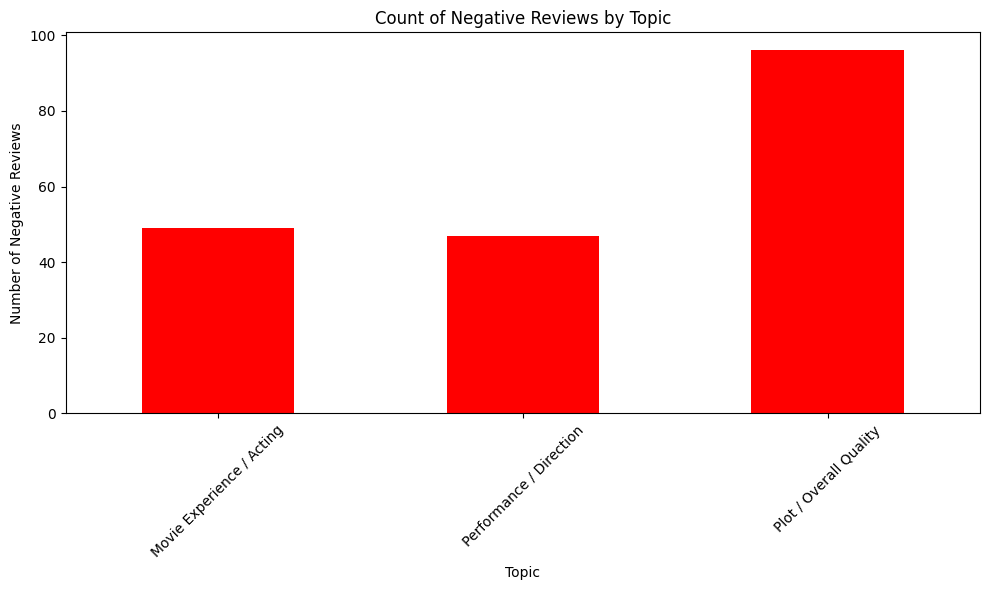

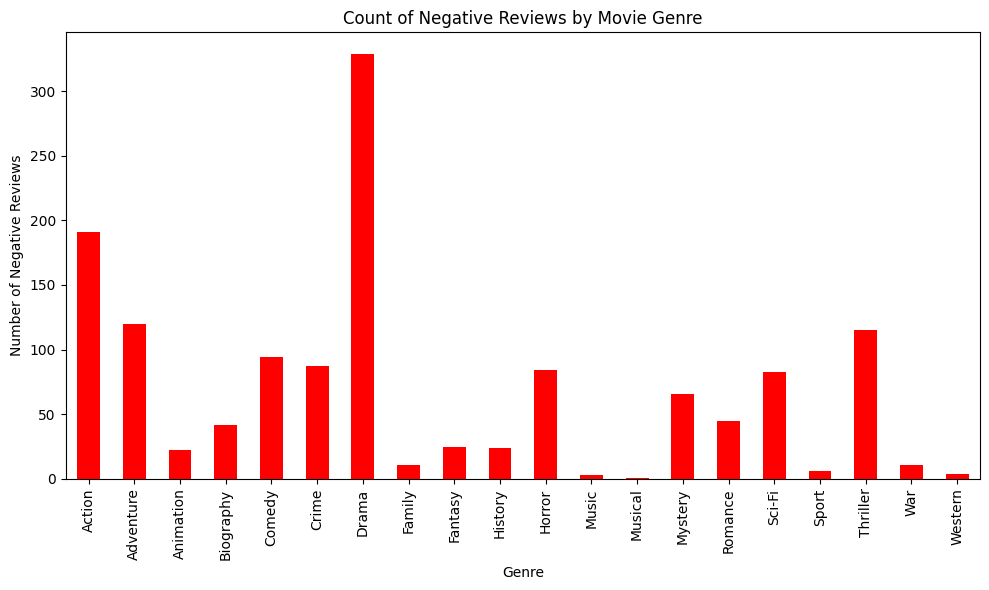

In [ ]:
#reviews with negative sentiment
negative_sentiment_reviews = reviews_df[reviews_df['Sentiment'] == 'Negative']
negative_sentiment_reviews

#movies of reviews with negative sentiment
negative_sentiment_movies = movies_final[movies_final['id'].isin(negative_sentiment_reviews['imdb_id'])]
negative_sentiment_movies

#topic modeling for negative reviews
# Adjust min_df and max_df for the smaller corpus size of negative reviews
neg_vectorizer = CountVectorizer(max_df=0.3, min_df=30, stop_words='english')

# Join the list of words back into a single string for CountVectorizer
processed_negative_text_for_lda = negative_sentiment_reviews['review'].apply(lambda x: ' '.join(x.split()))
# Use neg_vectorizer for fit_transform
vectorized_negative_text = neg_vectorizer.fit_transform(processed_negative_text_for_lda)

neg_lda_text = LatentDirichletAllocation(n_components=3, random_state=42)
neg_lda_text.fit(vectorized_negative_text)

feature_names = neg_vectorizer.get_feature_names_out()
term_frequency = np.sum(vectorized_negative_text, axis=0).tolist()[0]
# Use neg_lda_text and neg_vectorizer here
lda_data = pyLDAvis.lda_model.prepare(neg_lda_text, vectorized_negative_text, neg_vectorizer, vocab = feature_names, term_frequency = term_frequency, n_jobs = 1)

# Iterate through neg_lda_text.components_
for topic_idx, topic in enumerate(neg_lda_text.components_):
    print(f'Topic {topic_idx + 1}:')
    top_words_indices = topic.argsort()[:-11:-1]
    top_words = [feature_names[i] for i in top_words_indices]
    print(', '.join(top_words))
    print()

#Attach LDA outputs to negative reviews
# Create a temporary DataFrame for negative reviews to store their dominant topics
temp_neg_reviews = negative_sentiment_reviews.copy()

# Calculate topic distribution specifically for negative reviews
neg_doc_topic_dist = neg_lda_text.transform(vectorized_negative_text)

# Assign the dominant topic for each negative review
temp_neg_reviews['dominant_topic'] = neg_doc_topic_dist.argmax(axis=1)

# Aggregate to movie level and count topic distribution as percentages for negative reviews
neg_movie_topic_dist = (
    temp_neg_reviews
    .groupby('imdb_id')['dominant_topic']
    .value_counts(normalize=True)
    .unstack(fill_value=0)
)

# ensure all topics exist as columns
for i in range(neg_lda_text.n_components):
    if i not in neg_movie_topic_dist.columns:
        neg_movie_topic_dist[i] = 0

neg_movie_topic_dist = neg_movie_topic_dist.sort_index(axis=1)


# derive dominant topic + strength
neg_movie_topic_dist['main_topic'] = neg_movie_topic_dist.idxmax(axis=1)
neg_movie_topic_dist['topic_strength'] = neg_movie_topic_dist.max(axis=1)

#  entropy or uncertainty (diversity between topics)
neg_movie_topic_dist['topic_entropy'] = -np.sum(
    neg_movie_topic_dist.iloc[:, :-2] * np.log(neg_movie_topic_dist.iloc[:, :-2] + 1e-10),
    axis=1
)

#creating a dictionary of the topics for easier access
neg_topic_labels = {
    0: "Movie Experience / Acting",
    1: "Plot / Overall Quality",
    2: "Performance / Direction",
}

neg_movie_topic_dist['main_topic_label'] = neg_movie_topic_dist['main_topic'].map(neg_topic_labels)

#plot count of movie by topic
plt.figure(figsize=(10,6))
neg_movie_topic_dist.groupby('main_topic_label').size().plot(kind='bar', color='red')
plt.title('Count of Negative Reviews by Topic')
plt.xlabel('Topic')
plt.ylabel('Number of Negative Reviews')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#aggregating reviews with negative sentiment by movie genre

# Get movie IDs and their genres from 'movies_final'
movie_genres = movies_final[['id', 'genres']]

# Merge 'negative_sentiment_reviews' with 'movie_genres' to add genre info to each negative review
neg_reviews_with_movie_genres = negative_sentiment_reviews.merge(movie_genres, left_on='imdb_id', right_on='id', how='left')

# Explode the genres for reviews that belong to multiple genres
neg_reviews_with_exploded_genres = neg_reviews_with_movie_genres.assign(genre=neg_reviews_with_movie_genres['genres'].str.split(',')).explode('genre')
neg_reviews_with_exploded_genres['genre'] = neg_reviews_with_exploded_genres['genre'].str.strip()

# Now 'reviews_with_exploded_genres' has both 'Sentiment' and 'genre'.
# All sentiments here are 'Negative', so we can use .size() to count reviews per genre.
plt.figure(figsize=(10,6))
neg_reviews_with_exploded_genres.groupby('genre').size().plot(kind='bar', color='red')
plt.title('Count of Negative Reviews by Movie Genre') # Updated title for clarity
plt.xlabel('Genre')
plt.ylabel('Number of Negative Reviews') # Updated y-label for clarity
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

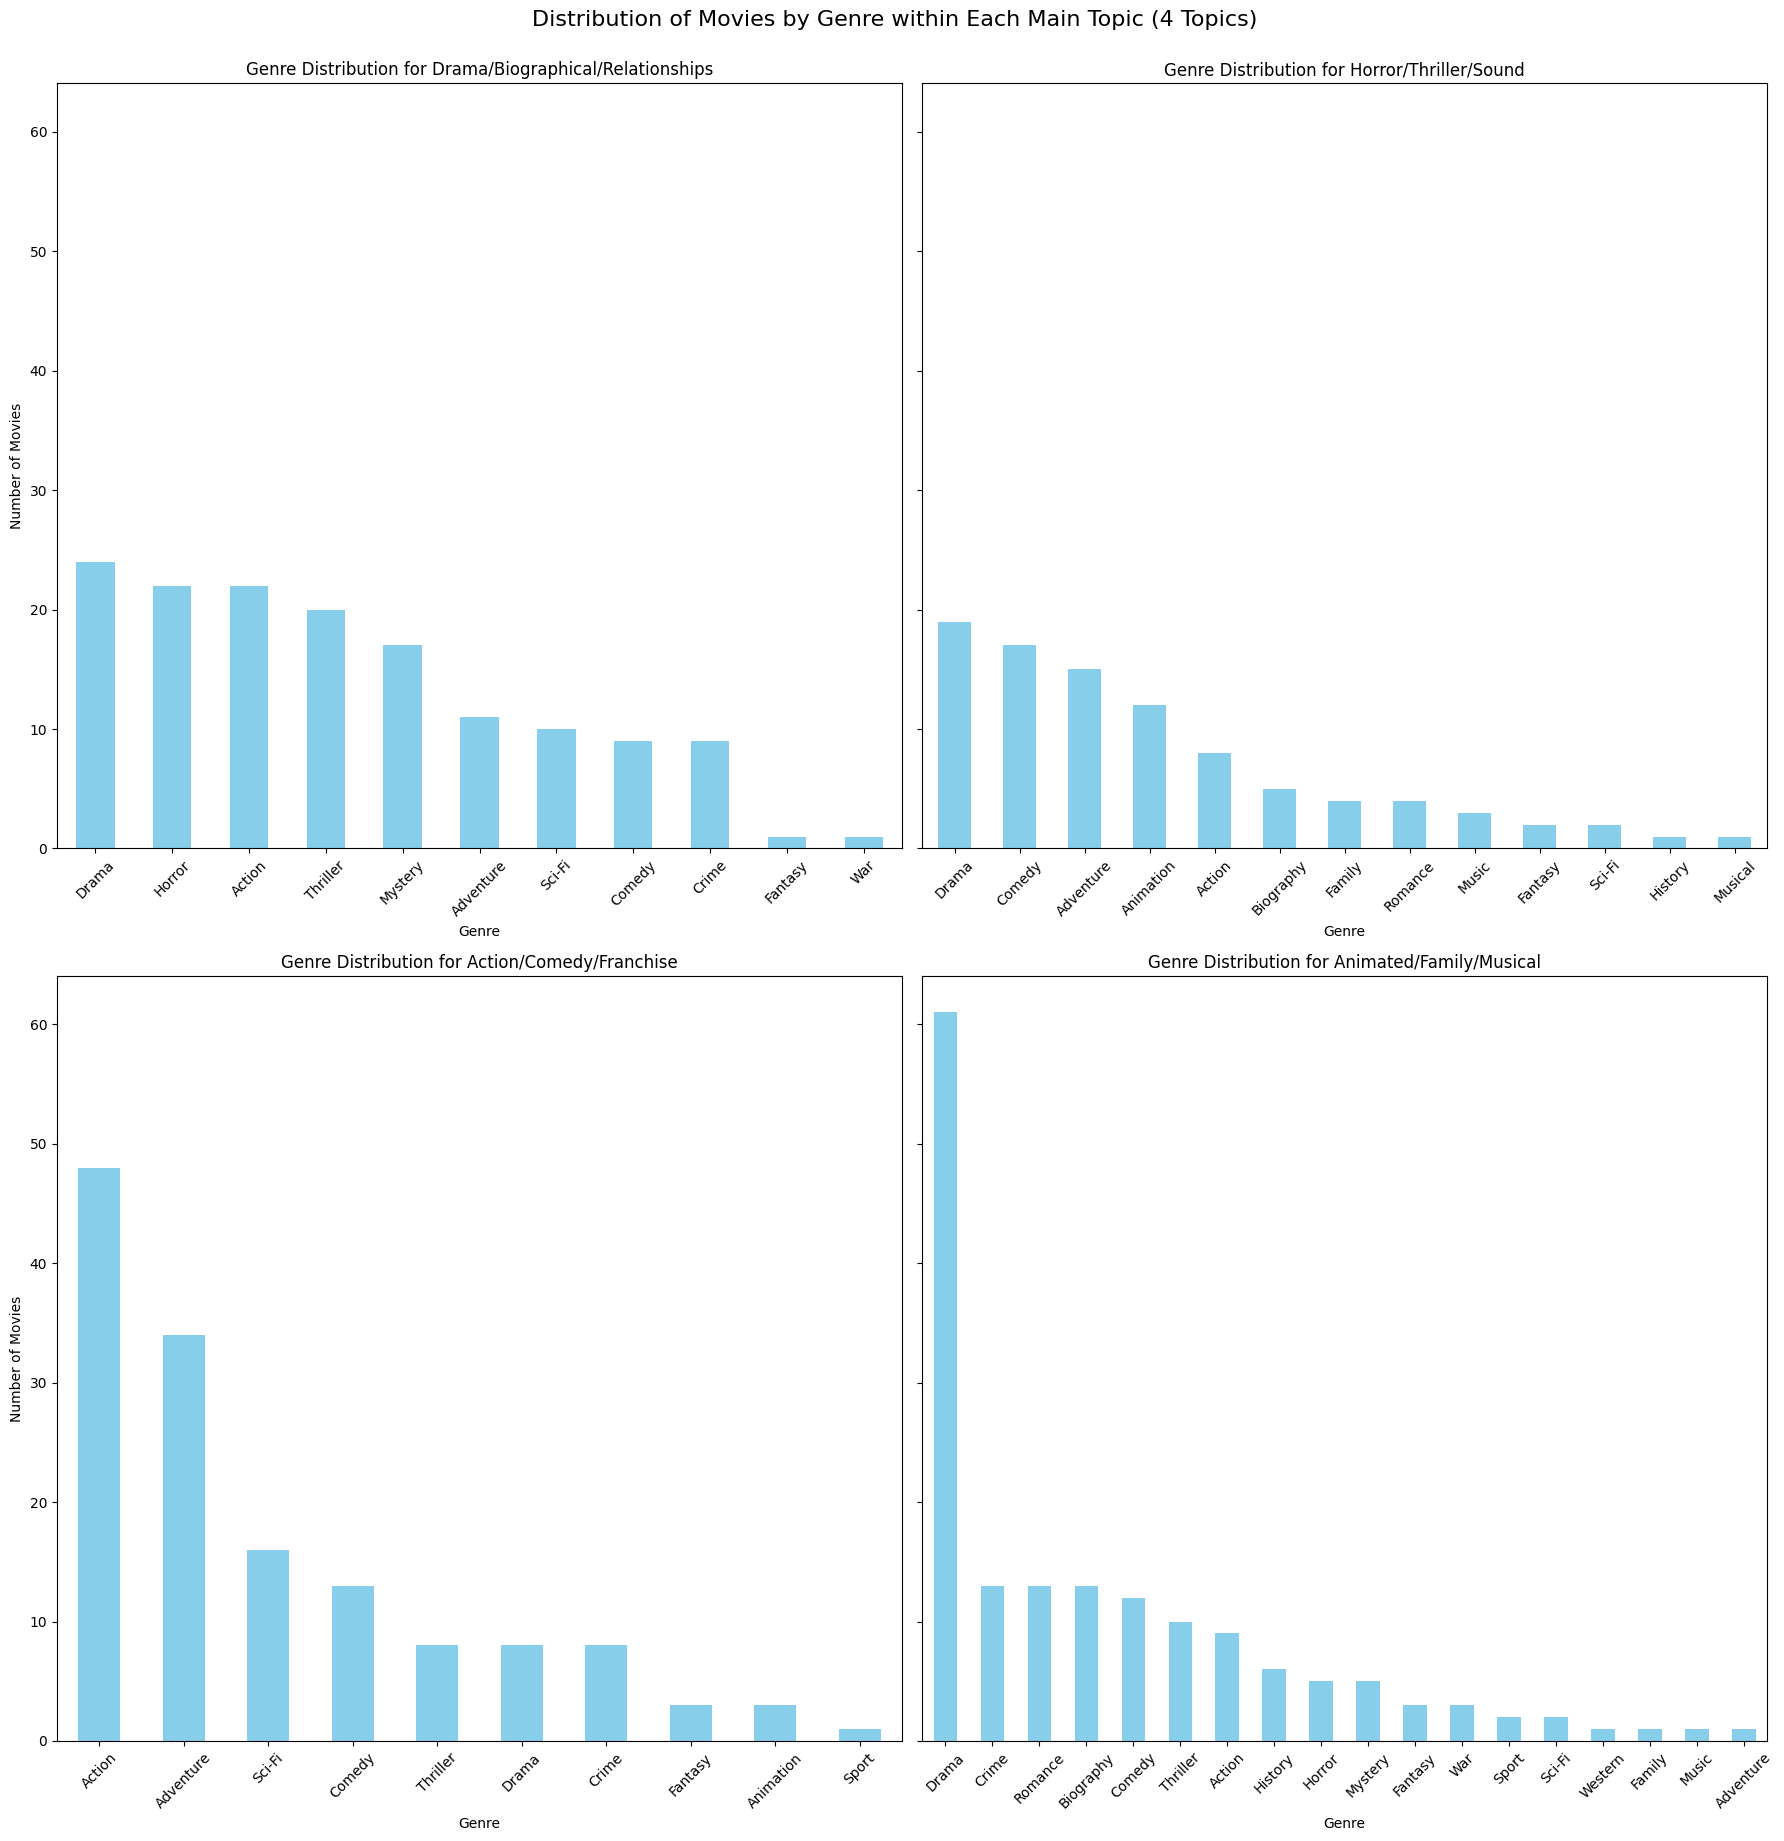

In [ ]:
# Get the unique main topics from movies_final
unique_main_topics = movies_final['main_topic_label'].unique()

# Create a 2x2 grid of subplots for 4 topics
fig, axes = plt.subplots(2, 2, figsize=(18, 18), sharey=True)
axes = axes.flatten() # Flatten the 2x2 array of axes for easier iteration

for i, topic_label in enumerate(unique_main_topics):
    # Filter movies for the current topic
    topic_movies = movies_final[movies_final['main_topic_label'] == topic_label]

    # Explode the genres for the filtered movies
    movies_with_exploded_genres_for_topic = topic_movies.assign(genre=topic_movies['genres'].str.split(',')).explode('genre')
    movies_with_exploded_genres_for_topic['genre'] = movies_with_exploded_genres_for_topic['genre'].str.strip()

    # Count the number of movies for each genre within this topic
    genre_counts = movies_with_exploded_genres_for_topic['genre'].value_counts()

    # Plot on the current subplot
    ax = axes[i]
    genre_counts.plot(kind='bar', ax=ax, color='skyblue')
    ax.set_title(f'Genre Distribution for {topic_label}')
    ax.set_xlabel('Genre')
    ax.set_ylabel('Number of Movies')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.suptitle('Distribution of Movies by Genre within Each Main Topic (4 Topics)', y=1.02, fontsize=16)
plt.show()

#Disproportionate amount of Drama movies skews these topics to include them because it may exist as an additional genre within a topic classified movie

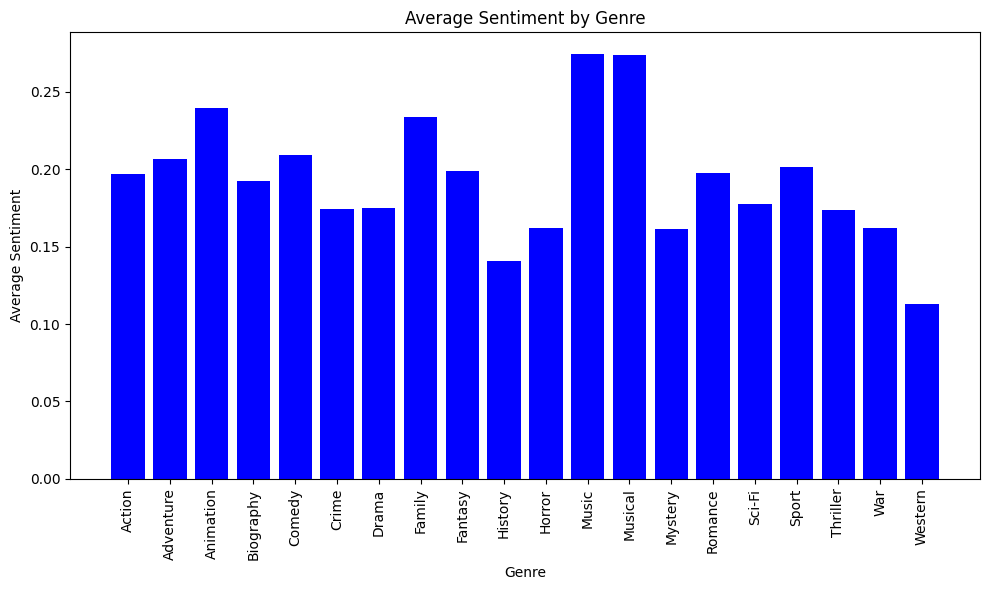

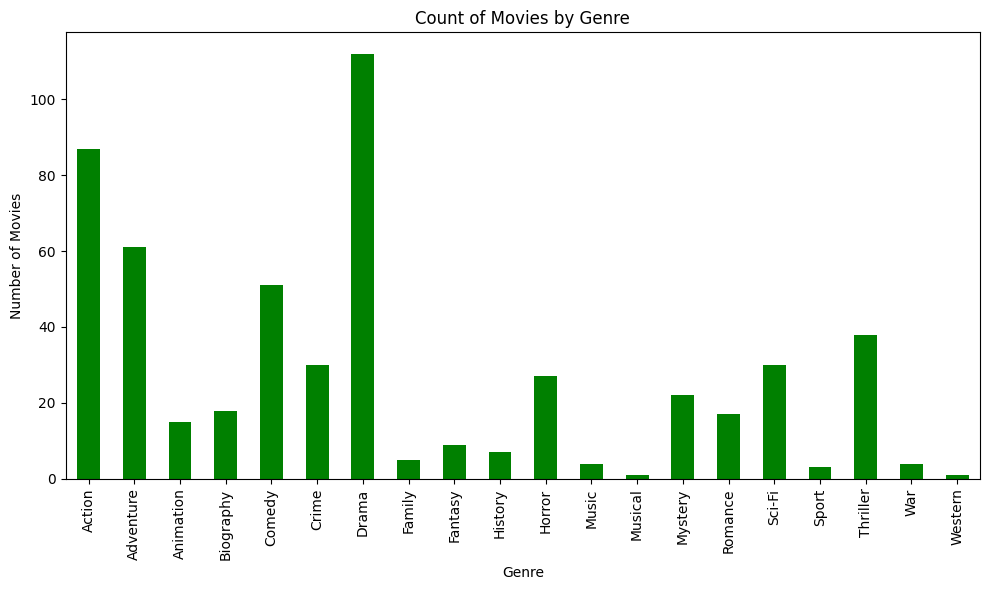

In [ ]:
#Visualization stuff
# Create a DataFrame where each row represents a movie-genre combination
movies_with_exploded_genres = movies_final.assign(genre=movies_final['genres'].str.split(',')).explode('genre')

# Clean up leading/trailing spaces in genre names
movies_with_exploded_genres['genre'] = movies_with_exploded_genres['genre'].str.strip()

# Calculate the average sentiment for each individual genre
avg_sentiment_by_genre = movies_with_exploded_genres.groupby('genre')['avg_sentiment'].mean()

#bar graph of avg_sentiment by genre
plt.figure(figsize=(10,6))
plt.bar(avg_sentiment_by_genre.index, avg_sentiment_by_genre.values, color='blue')
plt.title('Average Sentiment by Genre')
plt.xlabel('Genre')
plt.ylabel('Average Sentiment')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


#distribution of movies by genre
plt.figure(figsize=(10,6))
movies_with_exploded_genres.groupby('genre').size().plot(kind='bar', color='green')
plt.title('Count of Movies by Genre')
plt.xlabel('Genre')
plt.ylabel('Number of Movies')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

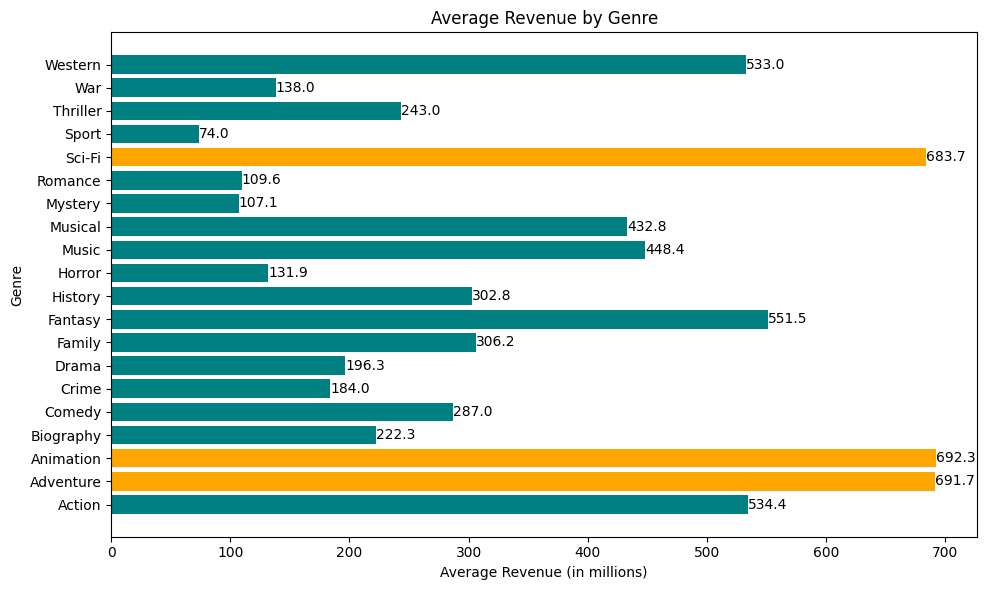

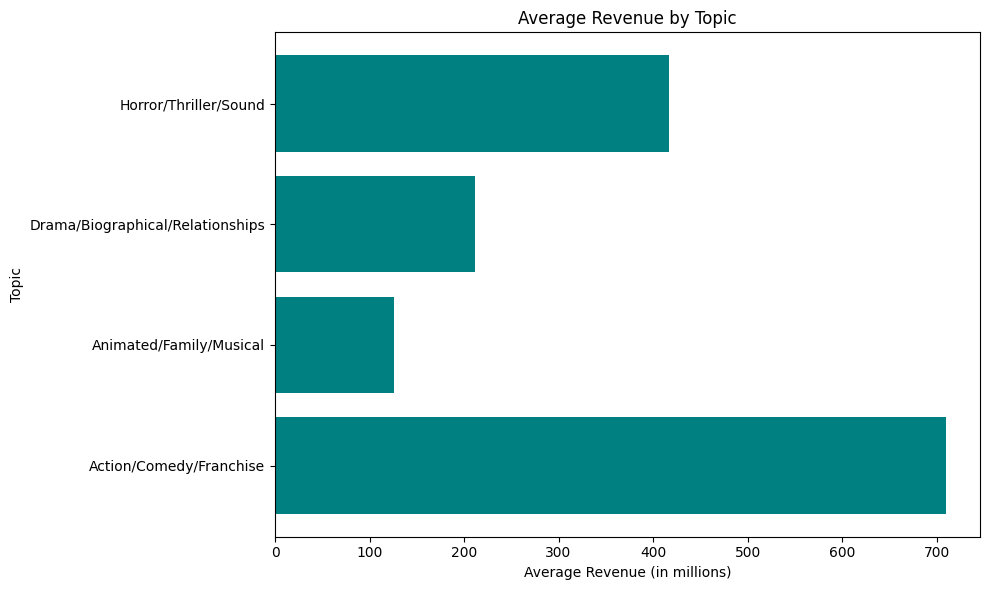

In [ ]:
# Calculate the average revenue for each individual genre
avg_revenue_by_genre = movies_with_exploded_genres.groupby('genre')['revenue'].mean()

# Sort genres by average revenue to identify the top N
sorted_genres = avg_revenue_by_genre.sort_values(ascending=False)
top_n_genres = sorted_genres.head(3).index.tolist()

# Create a color list for the bars
default_color = 'teal'
highlight_color = 'orange'
colors = [highlight_color if genre in top_n_genres else default_color for genre in avg_revenue_by_genre.index]

#horizontal bar chart visualization comparing avg revenue in millions to genre from movies_with_exploded_genres with value labels
plt.figure(figsize=(10,6))
bars = plt.barh(avg_revenue_by_genre.index, avg_revenue_by_genre.values, color=colors)
plt.title('Average Revenue by Genre')
plt.xlabel('Average Revenue (in millions)')
plt.ylabel('Genre')

# Add value labels
for bar in bars:
    plt.text(bar.get_width(), bar.get_y() + bar.get_height()/2,    # x, y position of text
             f'{bar.get_width()/1e6:,.1f}',                              # value to display (formatted in millions)
             va='center',                                         # vertical alignment
             ha='left'                                            # horizontal alignment
            )

# Define a formatter function for x-axis ticks to show values in millions
def millions_formatter(x, pos):
    return f'{x / 1e6:,.0f}'

# Apply the custom formatter to the x-axis
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(millions_formatter))

plt.tight_layout()
plt.show()



#Average revenue by topic
avg_revenue_by_topic = movies_final.groupby('main_topic_label')['revenue'].mean()

#horizontal bar chart showing avg revenue by topic
plt.figure(figsize=(10,6))
bars = plt.barh(avg_revenue_by_topic.index, avg_revenue_by_topic.values, color='teal')
plt.title('Average Revenue by Topic')
plt.xlabel('Average Revenue (in millions)')
plt.ylabel('Topic')
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(millions_formatter))
plt.tight_layout()
plt.show()


#NOTE THAT THIS IS SKEWED IN COMPARISON TO THE PURE GENRE DISTRIBUTION DUE TO THESE TOPICS CONTAINING FILMS ACROSS DIFFERENT GENRES

In [ ]:
def recommend_movies(df, genre=None, topic=None, top_n=5):

    data = df.copy()

    # filter by genre
    if genre:
        data = data[data['genres'].str.contains(genre, case=False, na=False)]

    # filter by topic
    if isinstance(topic, int):
            data = data[data['main_topic'] == topic]
    else:
        data = data[data['main_topic_label'] == topic]

    # ranking unbiased scores
    result = (
        data.sort_values('final_score', ascending=False)
        .head(top_n)
        [['title', 'genres', 'main_topic_label',
          'weighted_rating', 'avg_sentiment', 'final_score']]
    )

    return result

In [ ]:
#recommendation code for displaying choices and running the function

#Print a list of individual genres from the movies
print(f"Movie genres: {movies_final['genres'].str.split(',').explode().str.strip().unique()}")
print()

# Create a reverse mapping for easier topic input
topic_name_to_id = {v: k for k, v in topic_labels.items()}

# Set pandas display options to show all columns on one line and prevent wrapping
pd.set_option('display.width', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.expand_frame_repr', False)

#initialize loop to allow for repeated queries
active = True
while(active == True):
  #User inputs a genre to recommend movies or enter ! to exit loop
  genre = input("Enter a genre to recommend movies (or enter ! to exit): ")
  if genre == "!":
    active = False
  else:
    print(f"\nYou selected Genre: {genre}")
    print("\nAvailable topics by ID or name:")
    for topic_id, topic_name in topic_labels.items():
        print(f"  {topic_id}: {topic_name}")
    topic_input = input("\nEnter a topic ID (0-3) or full topic name (or enter ! to exit): ")
    if topic_input == "!":
      active = False
    else:
      # Determine if input is an ID or a name
      try:
        topic = int(topic_input)
        selected_topic_label = topic_labels[topic] # Get label if ID is entered
      except ValueError:
        topic = topic_input
        selected_topic_label = topic # Use input as label if name is entered

      print(f"\nYou selected Topic: {selected_topic_label}\n")
      #Call recommendation function
      recommendations = recommend_movies(movies_final, genre=genre, topic=topic, top_n=5)
      if not recommendations.empty:
          print(recommendations)
      else:
          print(f"\nNo movies found for genre '{genre}' and topic '{selected_topic_label}'. Please try a different combination.")
      print()

Movie genres: ['Action' 'Adventure' 'Sci-Fi' 'Comedy' 'Drama' 'Thriller' 'Crime'
 'Mystery' 'Biography' 'Western' 'Fantasy' 'Horror' 'Romance' 'Sport'
 'Animation' 'Family' 'History' 'Music' 'Musical' 'War']

